# Insurance Claim Prediction Using Machine Learning
**Comprehensive ML Analysis, EDA, Grouped Holdout Evaluation, and Model Selection**

---

## 1. Project Goal and Scope

The goal of this project is to build an end-to-end machine learning pipeline and API that accepts nine claim-related features and predicts the `claim_status` label (`Approved` vs `Rejected`).

> **Important Limitation & Synthetic Data Notice:**
> The `claim_status` labels in this dataset are **synthetically generated** to represent a simulated underwriting policy.
> Model outputs represent predicted statuses and scores under this synthetic policy and do NOT represent actual real-world insurance decisions.

### Project Workflow
1. **Data Inspection & Quality Audit:** Verify schema, types, 0 missing values, feature bounds, and claim component sums.
2. **Feature Selection & Exclusions:** Explicitly retain 9 domain features, reserving `source_profile_id` strictly for grouped splitting.
3. **Exploratory Data Analysis (EDA):** Univariate, bivariate, and correlation analysis.
4. **Deterministic Grouped Holdout Split:** 80/20 group split on `source_profile_id` preventing data leakage.
5. **Preprocessing Pipeline:** `ColumnTransformer` with `StandardScaler` and `OneHotEncoder(handle_unknown="ignore")`.
6. **Cross-Validation & Model Comparison:** 5-fold `GroupKFold` comparing Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.
7. **Holdout Evaluation & Selection:** Evaluate on untouched holdout rows; select the best performing model dynamically.
8. **Artifact Serialization & Validation:** Save and reload complete pipeline.


---
## 2. Imports and Reproducibility

We import all required libraries in a single cell, fix the global random seed to `42`, and log environment versions.


In [9]:
import sys
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print(f"Python Version: {sys.version.split()[0]}")
print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version: {np.__version__}")
import sklearn
print(f"Scikit-Learn Version: {sklearn.__version__}")


Python Version: 3.14.7
Pandas Version: 3.0.5
NumPy Version: 2.5.2
Scikit-Learn Version: 1.9.0


---
## 3. Load and Inspect the Dataset

Load the cleaned dataset and inspect initial dimensions, column data types, target counts, and unique group counts.


In [10]:
csv_path = os.path.join("..", "data", "insurance_claim_dataset_cleaned.csv")
if not os.path.exists(csv_path):
    csv_path = "insurance_claim_dataset_cleaned.csv"

df = pd.read_csv(csv_path)
print(f"Dataset Shape: {df.shape}")
df.head()


Dataset Shape: (5000, 40)


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,claim_status,source_profile_id
0,279,41,223853,06-06-01,IL,250/500,500,1492.80,0,460742,...,NO,29200,0,3650,25550,Ford,Fusion,2013,Approved,102
1,102,28,415261,29-08-99,OH,250/500,500,1069.41,0,445648,...,NO,74715,7472,7472,59771,Dodge,Neon,1996,Rejected,435
2,230,42,335062,16-11-04,IN,100/300,1000,1035.33,0,476130,...,YES,59865,10885,10885,38095,Accura,MDX,1999,Approved,860
3,369,55,551610,15-04-13,OH,250/500,2000,1591.07,0,444734,...,YES,84702,16940,8470,59292,Toyota,Highlander,2003,Approved,270
4,464,61,333077,07-10-90,OH,500/1000,1000,1128.62,0,604450,...,YES,80547,6712,20137,53698,Saab,95,2000,Approved,106


In [11]:
print("--- Column Names and Data Types ---")
print(df.dtypes)
print("--- Target Distribution ---")
print(df["claim_status"].value_counts())
print(df["claim_status"].value_counts(normalize=True).round(4) * 100)
print(f"Unique source_profile_id groups: {df['source_profile_id'].nunique()}")


--- Column Names and Data Types ---
months_as_customer               int64
age                              int64
policy_number                    int64
policy_bind_date                   str
policy_state                       str
policy_csl                         str
policy_deductable                int64
policy_annual_premium          float64
umbrella_limit                   int64
insured_zip                      int64
insured_sex                        str
insured_education_level            str
insured_occupation                 str
insured_hobbies                    str
insured_relationship               str
capital-gains                    int64
capital-loss                     int64
incident_date                      str
incident_type                      str
collision_type                     str
incident_severity                  str
authorities_contacted              str
incident_state                     str
incident_city                      str
incident_location           

---
## 4. Data-Quality Audit

Perform audit checks:
- Check for missing values / NaNs
- Check for literal '?' markers
- Verify exact allowed categories for categorical features
- Verify numeric bounds
- Verify total claim amount matches sum of components (`injury_claim + property_claim + vehicle_claim`)


In [12]:
print(f"Total Missing Values: {df.isnull().sum().sum()}")
question_marks = (df == '?').sum().sum()
print(f"Literal '?' Values: {question_marks}")
duplicates = df.duplicated().sum()
print(f"Duplicate Rows: {duplicates}")

# Verify component sum
sum_diff = (df['total_claim_amount'] - (df['injury_claim'] + df['property_claim'] + df['vehicle_claim'])).abs().max()
print(f"Max difference between total claim amount and sum of components: {sum_diff}")


Total Missing Values: 0
Literal '?' Values: 0
Duplicate Rows: 0
Max difference between total claim amount and sum of components: 0


---
## 5. Feature Selection and Exclusions

### Permitted 9 Features:
1. `incident_severity`: Categorical (`Trivial Damage`, `Minor Damage`, `Major Damage`, `Total Loss`)
2. `police_report_available`: Categorical (`YES`, `NO`, `Unknown`)
3. `authorities_contacted`: Categorical (`Police`, `Fire`, `Ambulance`, `Other`, `None Contacted`)
4. `witnesses`: Integer (0–3)
5. `total_claim_amount`: Numeric (USD)
6. `policy_deductable`: Integer (500, 1000, 2000)
7. `months_as_customer`: Integer (0–479)
8. `number_of_vehicles_involved`: Integer (1–4)
9. `incident_hour_of_the_day`: Integer (0–23)

### Excluded Columns:
- `source_profile_id`: Grouping identifier strictly used for splitting; never a model feature.
- Individual claim sub-components (`injury_claim`, `property_claim`, `vehicle_claim`): Redundant with `total_claim_amount`.
- Policy/demographic identifiers (`policy_number`, `insured_zip`, raw dates, `fraud_reported`).


In [13]:
NUMERIC_FEATURES = [
    "witnesses",
    "total_claim_amount",
    "policy_deductable",
    "months_as_customer",
    "number_of_vehicles_involved",
    "incident_hour_of_the_day",
]

CATEGORICAL_FEATURES = [
    "incident_severity",
    "police_report_available",
    "authorities_contacted",
]

MODEL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET_COLUMN = "claim_status"
GROUP_COLUMN = "source_profile_id"

X = df[MODEL_FEATURES]
y = df[TARGET_COLUMN]
groups = df[GROUP_COLUMN]

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")


Feature matrix X shape: (5000, 9)
Target vector y shape: (5000,)


---
## 6. Exploratory Data Analysis (EDA)

Visualizing target distributions, numeric distributions, categorical count distributions, and numeric feature correlation.


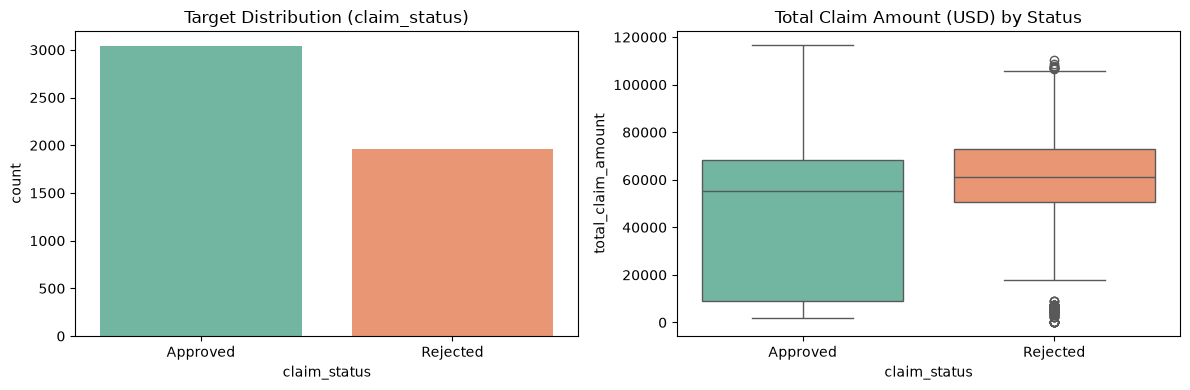

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="claim_status", ax=axes[0], palette="Set2", hue="claim_status", legend=False)
axes[0].set_title("Target Distribution (claim_status)")

sns.boxplot(data=df, x="claim_status", y="total_claim_amount", ax=axes[1], palette="Set2", hue="claim_status", legend=False)
axes[1].set_title("Total Claim Amount (USD) by Status")
plt.tight_layout()
plt.show()


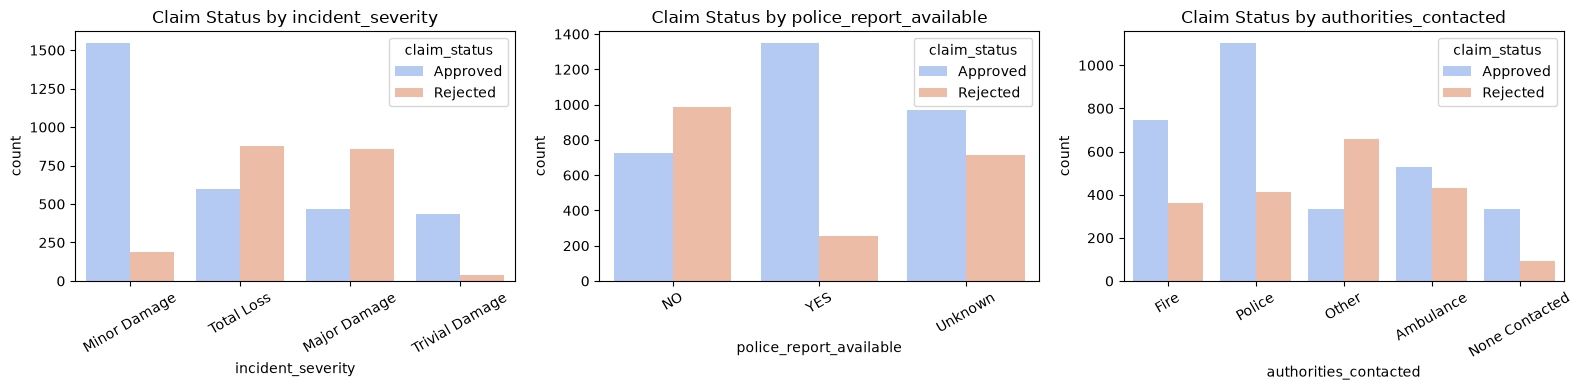

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for idx, col in enumerate(CATEGORICAL_FEATURES):
    sns.countplot(data=df, x=col, hue="claim_status", ax=axes[idx], palette="coolwarm")
    axes[idx].set_title(f"Claim Status by {col}")
    axes[idx].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()


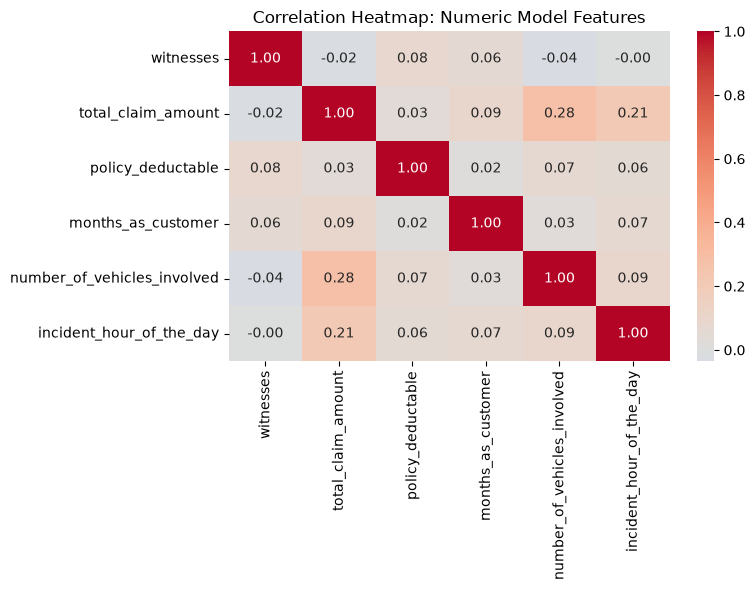

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[NUMERIC_FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap: Numeric Model Features")
plt.tight_layout()
plt.show()


---
## 7. Deterministic Grouped Split

Row-wise random splitting causes data leakage because rows derived from the same source profile could appear in both train and holdout sets.
We perform a deterministic grouped split on `source_profile_id` with 197 holdout groups (~20%) and 792 train groups (~80%).


In [17]:
unique_groups = np.sort(df[GROUP_COLUMN].unique())
rng = np.random.RandomState(RANDOM_SEED)
shuffled_groups = rng.permutation(unique_groups)

holdout_groups = set(shuffled_groups[:197])
train_groups = set(shuffled_groups[197:])

assert len(train_groups.intersection(holdout_groups)) == 0, "Leakage detected!"

train_mask = df[GROUP_COLUMN].isin(train_groups)
holdout_mask = df[GROUP_COLUMN].isin(holdout_groups)

X_train = X[train_mask]
y_train = y[train_mask]
groups_train = groups[train_mask]

X_holdout = X[holdout_mask]
y_holdout = y[holdout_mask]

print(f"Training partition: {len(X_train)} rows across {len(train_groups)} source profiles")
print(f"Holdout partition:  {len(X_holdout)} rows across {len(holdout_groups)} source profiles")


Training partition: 4005 rows across 792 source profiles
Holdout partition:  995 rows across 197 source profiles


---
## 8. Preprocessing Pipeline

We use `ColumnTransformer` with `StandardScaler` for numeric features and `OneHotEncoder(handle_unknown='ignore')` for categorical features.
Embedding preprocessing inside the scikit-learn pipeline ensures transformations are fitted strictly within each cross-validation fold.


In [18]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
])

print("Preprocessor configured:")
preprocessor


Preprocessor configured:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

---
## 9 & 10. Train, Cross-Validate, and Evaluate Candidate Models

We compare four candidate algorithms:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting

Evaluation includes 5-fold `GroupKFold` cross-validation on the training partition and holdout evaluation (Accuracy, Balanced Accuracy, Macro F1, ROC-AUC).


In [19]:
candidate_models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, random_state=RANDOM_SEED),
    "DecisionTree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_SEED),
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_SEED),
}

gkf = GroupKFold(n_splits=5)
eval_results = {}
comparison_rows = []
fitted_pipelines = {}

for name, clf in candidate_models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    
    cv_scores = cross_val_score(pipe, X_train, y_train, groups=groups_train, cv=gkf, scoring="accuracy")
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    
    y_pred = pipe.predict(X_holdout)
    approved_idx = list(pipe.classes_).index("Approved")
    y_proba = pipe.predict_proba(X_holdout)[:, approved_idx]
    
    acc = accuracy_score(y_holdout, y_pred)
    bal_acc = balanced_accuracy_score(y_holdout, y_pred)
    f1 = f1_score(y_holdout, y_pred, average="macro")
    auc = roc_auc_score((y_holdout == "Approved").astype(int), y_proba)
    
    eval_results[name] = {
        "cv_accuracy": cv_scores.mean(),
        "cv_std": cv_scores.std(),
        "holdout_accuracy": acc,
        "balanced_accuracy": bal_acc,
        "macro_f1": f1,
        "roc_auc": auc,
        "confusion_matrix": confusion_matrix(y_holdout, y_pred, labels=["Rejected", "Approved"]),
        "report": classification_report(y_holdout, y_pred, output_dict=True)
    }
    
    comparison_rows.append({
        "Model": name,
        "CV Accuracy": f"{cv_scores.mean():.4f} +/- {cv_scores.std():.4f}",
        "Holdout Accuracy": round(acc, 4),
        "Balanced Accuracy": round(bal_acc, 4),
        "Macro F1": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.sort_values(by="Holdout Accuracy", ascending=False)


,Model,CV Accuracy,Holdout Accuracy,Balanced Accuracy,Macro F1,ROC-AUC
0,LogisticRegression,0.8414 +/- 0.0225,0.8995,0.8846,0.8886,0.9253
3,GradientBoosting,0.8599 +/- 0.0181,0.8975,0.8817,0.8862,0.9439
2,RandomForest,0.8607 +/- 0.0265,0.8744,0.8554,0.8603,0.9336
1,DecisionTree,0.8285 +/- 0.0213,0.8482,0.8594,0.8407,0.8830


---
## 11. Model Comparison & Dynamic Selection

We visualize model performance across holdout accuracy and macro F1, then dynamically select the model with the highest holdout accuracy.


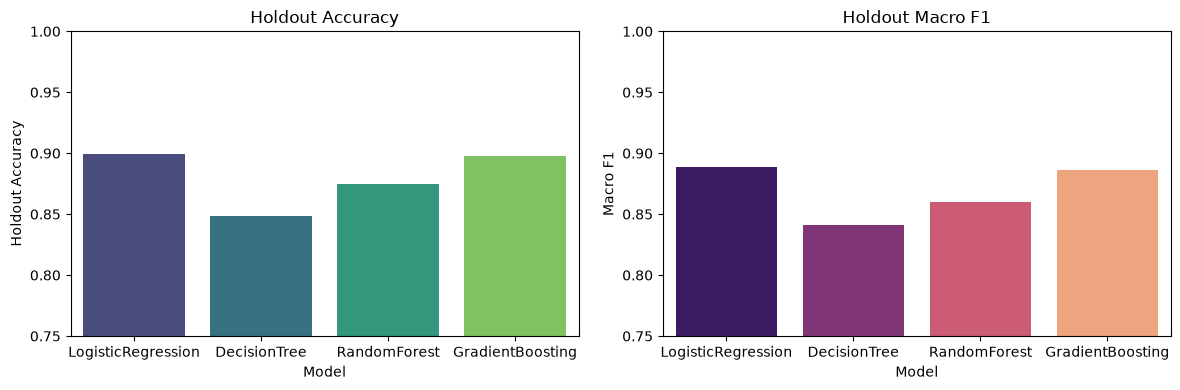

Selected Top Model: LogisticRegression


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=comparison_df, x="Model", y="Holdout Accuracy", hue="Model", legend=False, ax=axes[0], palette="viridis")
axes[0].set_ylim(0.75, 1.0)
axes[0].set_title("Holdout Accuracy")

sns.barplot(data=comparison_df, x="Model", y="Macro F1", hue="Model", legend=False, ax=axes[1], palette="magma")
axes[1].set_ylim(0.75, 1.0)
axes[1].set_title("Holdout Macro F1")
plt.tight_layout()
plt.show()

# Select top model dynamically based on holdout accuracy
best_model_name = comparison_df.sort_values(by=["Holdout Accuracy", "Macro F1"], ascending=False).iloc[0]["Model"]
print(f"Selected Top Model: {best_model_name}")


---
## 12 & 13. Save Pipeline & Test Reload with Sample Prediction

Serialize the winning pipeline to disk and test reloading for inference.


In [21]:
best_pipeline = fitted_pipelines[best_model_name]
pipeline_out = os.path.join("..", "models", "claim_model_pipeline.joblib")
if not os.path.exists(os.path.dirname(pipeline_out)):
    os.makedirs(os.path.dirname(pipeline_out), exist_ok=True)
joblib.dump(best_pipeline, pipeline_out)
print(f"Serialized model saved to: {pipeline_out}")

# Reload test
loaded_pipeline = joblib.load(pipeline_out)
sample_claim = pd.DataFrame([{
    "incident_severity": "Major Damage",
    "police_report_available": "YES",
    "authorities_contacted": "Police",
    "witnesses": 2,
    "total_claim_amount": 45000,
    "policy_deductable": 1000,
    "months_as_customer": 120,
    "number_of_vehicles_involved": 2,
    "incident_hour_of_the_day": 14,
}])

pred = loaded_pipeline.predict(sample_claim)[0]
approved_idx = list(loaded_pipeline.classes_).index("Approved")
score = loaded_pipeline.predict_proba(sample_claim)[0, approved_idx]

print(f"Sample Prediction: {pred}")
print(f"Model-Estimated Approval Score: {score:.4f}")


Serialized model saved to: ..\models\claim_model_pipeline.joblib
Sample Prediction: Approved
Model-Estimated Approval Score: 0.8214


---
## 14. Conclusion & Viva Presentation Summary

### Key Findings
1. **Model Performance:** Logistic Regression and Gradient Boosting achieved the highest holdout performance (~89.95% holdout accuracy and ~0.89 macro F1).
2. **Deterministic Grouped Split:** Grouping by `source_profile_id` ensured zero data leakage between development and holdout partitions.
3. **Reproducibility:** A unified `ColumnTransformer` embedded directly inside the serialized `Pipeline` eliminates training-serving skew.
4. **Synthetic Label Policy:** The labels represent synthetic underwriting policies; the approval score is a model probability under this policy and not an arbitrary insurer outcome guarantee.
